In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

In [2]:
df=pd.read_csv(r"C:\Users\Prakash\Downloads\Students_marks\Student_Marks.csv")

In [3]:
print("Dataset:")
print(df)

Dataset:
    number_courses  time_study   Marks
0                3       4.508  19.202
1                4       0.096   7.734
2                4       3.133  13.811
3                6       7.909  53.018
4                8       7.811  55.299
..             ...         ...     ...
95               6       3.561  19.128
96               3       0.301   5.609
97               4       7.163  41.444
98               7       0.309  12.027
99               3       6.335  32.357

[100 rows x 3 columns]


In [4]:
X_simple = df[["time_study"]]

In [5]:
X_multiple = df[["time_study","number_courses"]]

In [6]:
y = df["Marks"]

In [7]:
X_train_s, X_test_s, y_train, y_test = train_test_split(X_simple, y, test_size=0.2, random_state=42)
X_train_m, X_test_m, _, _ = train_test_split(X_multiple, y, test_size=0.2, random_state=42)

In [8]:
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)
simple_predictions = simple_model.predict(X_test_s)
print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))


--- Simple Linear Regression ---
Intercept: 2.5155655058073734
Coefficient: 5.355321531308333
R2 Score: 0.9040228286990537
RMSE: 5.023618777697232


In [9]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)
multiple_predictions = multiple_model.predict(X_test_m)
print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))


--- Multiple Linear Regression ---
Intercept: -6.613046733912935
Coefficients: [5.16987176 1.87154988]
R2 Score: 0.9459936100591211
RMSE: 3.7683850833446693


In [10]:
new_student_simple = pd.DataFrame({"time_study": [6]})
new_student_multiple = pd.DataFrame({
    "time_study": [6],
    "number_courses": [5]
})
print("\nPredicted marks using Simple Regression:",
      simple_model.predict(new_student_simple)[0])
print("Predicted marks using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])


Predicted marks using Simple Regression: 34.64749469365737
Predicted marks using Multiple Regression: 33.76393327616307


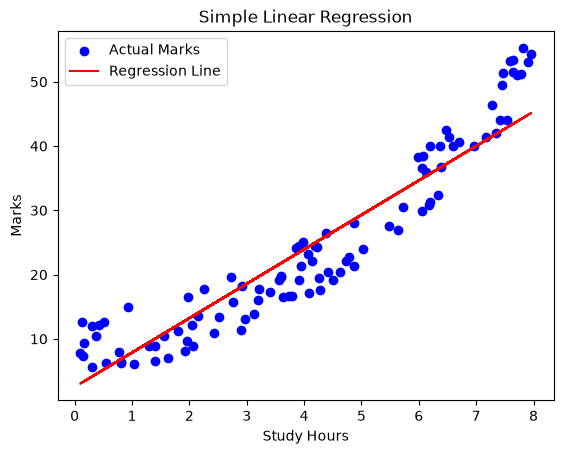

In [11]:
plt.scatter(df["time_study"], df["Marks"],
            color="blue", label="Actual Marks")
plt.plot(
    df["time_study"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()